# Motifs from contribution scores

A model's contribution scores show which bases it relied on. The short
stretches of high contribution, or seqlets, hold the sites of the factors it
has learned about. TF-MoDISco gathers seqlets that look alike into patterns.
This guide finds the same motifs a different way: it calls seqlets and runs
motif discovery on their letters.
[`contribution_motifs()`][universalmotif.contribution_motifs] does every step
in one call.

We use the chromBPNet model of ATAC-seq in K562 cells from the
[motifs and deep learning](deep-learning.ipynb) guide, and compare what we
find with the model's own [TF-MoDISco results](tfmodisco.ipynb).

In [1]:
import pathlib
import tarfile
import time
import urllib.request

import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need the regions the model was interpreted on, its contribution scores
and the sequence of chromosome 1. To compare with, we also need the model's
TF-MoDISco results and the JASPAR 2024 vertebrate motifs. The contribution
scores are a bigWig track of 2.1 GB. Reading thousands of regions from
ENCODE's server would take hours, so the track is downloaded once:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

ENCODE = "https://www.encodeproject.org/files"
regions_path = fetch(f"{ENCODE}/ENCFF834JBL/@@download/ENCFF834JBL.bed.gz")
scores_path = fetch(f"{ENCODE}/ENCFF407GCO/@@download/ENCFF407GCO.bigWig")
modisco_tar = fetch(f"{ENCODE}/ENCFF009WUL/@@download/ENCFF009WUL.tar.gz")
chr1_path = fetch("https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr1.fa.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

modisco_path = CACHE / "counts" / "tfmodisco.raw_output.counts.ENCSR868FGK.hd5"
if not modisco_path.exists():
    with tarfile.open(modisco_tar) as tar:
        tar.extract(f"counts/{modisco_path.name}", CACHE, filter="data")

## The regions

The model was interpreted on 1 kb windows around accessible regions. We take
those on chromosome 1 and keep the middle 500 bases of each, where most of
the contribution is. Windows that overlap one kept before are dropped, so no
base is counted twice:

In [3]:
regions = um.read_bed(regions_path).filter(pl.col("chrom") == "chr1").sort("start")
mid = (regions["start"] + regions["end"]) // 2
windows = pl.DataFrame({"chrom": "chr1", "start": mid - 250, "end": mid + 250})
keep, last = [], -1
for s, e in windows.select("start", "end").iter_rows():
    if s >= last:
        keep.append(True)
        last = e
    else:
        keep.append(False)
windows = windows.filter(pl.Series(keep))
print(regions.height, "regions,", windows.height, "windows kept")

31165 regions, 21292 windows kept


[`signal_values()`][universalmotif.signal_values] reads the score of every
base of each window from the track.
[`extract_ranges()`][universalmotif.extract_ranges] reads the windows'
sequences from chromosome 1:

In [4]:
chr1 = um.read_fasta(chr1_path)
seqs = [s.upper() for s in um.extract_ranges(chr1, windows).values()]
scores = np.stack([um.signal_values(scores_path, c, s, e) for c, s, e in windows.iter_rows()])
scores.shape

(21292, 500)

## Finding the motifs

`contribution_motifs()` takes the scores and their sequences. By default it
searches the positive seqlets, those of bases that raised the prediction. It
works in these steps:

1. It calls seqlets with [`call_seqlets()`][universalmotif.call_seqlets].
2. It searches their letters with
   [`motif_finder()`][universalmotif.motif_finder], against windows away
   from any seqlet.
3. It rebuilds each motif from its sites in the seqlets with
   [`refine_motifs()`][universalmotif.refine_motifs].
4. It keeps the motifs that reach enough new seqlets with
   [`select_motifs()`][universalmotif.select_motifs], leaving out repeats.
5. It searches again in the seqlets that no motif reaches yet.
6. It looks for composite motifs, two parts with a spacer, with
   [`gapped_motif_finder()`][universalmotif.gapped_motif_finder].
7. It finds where the model used each motif, as described below.

In [5]:
t = time.time()
found = um.contribution_motifs(scores, seqs, seed=1, nthreads=2)
print(f"{found!r} in {time.time() - t:.1f} s")
found.motifs.select("name", "pattern", "source", "consensus", "seqlets")

ContributionMotifs(29 motifs in 20 patterns from 16,378 seqlets) in 8.0 s


name,pattern,source,consensus,seqlets
str,str,str,str,i64
"""pos_1""","""pos_p2""","""seqlets""","""CCASYAGRKGGCRS""",2497
"""pos_2""","""pos_p1""","""seqlets""","""GCYCCGCCCCY""",2245
"""pos_4""","""pos_p3""","""seqlets""","""RTGACTCAB""",1442
"""pos_3""","""pos_p5""","""seqlets""","""RNAGATAAGR""",1027
"""pos_r30""","""pos_p1""","""seqlets""","""CNSCNAGCYCCGCCTCCCNGSNNCNCNCC""",2201
"""pos_11""","""pos_p4""","""seqlets""","""ACTTCCTSTTY""",722
"""pos_12""","""pos_p6""","""seqlets""","""MTGATGCAAY""",437
"""pos_13""","""pos_p10""","""seqlets""","""RGCCAATSRGA""",402
"""pos_r9""","""pos_p9""","""seqlets""","""NYTGGCASNNRGCCARG""",430


Each motif comes as a PPM in the `motif` column and as a CWM in the `cwm`
column. The CWM is the mean contribution of each letter at the motif's sites
in the seqlets. `seqlets` counts the seqlets the motif reaches. Names
starting with `pos_r` come from the second search, and those starting with
`pos_g` are composites.

## Patterns

Some motifs are spellings of one site that each reach seqlets the others
miss. `patterns` gathers motifs whose CWMs are alike, with a cosine of 0.8 or
more, under the one that reaches the most seqlets. This is much like the
patterns of TF-MoDISco:

In [6]:
found.patterns.select("pattern", "representative", "consensus", "seqlets", "members")

pattern,representative,consensus,seqlets,members
str,str,str,i64,list[str]
"""pos_p1""","""pos_2""","""GCYCCGCCCCY""",3697,"[""pos_2"", ""pos_r30"", … ""pos_24""]"
"""pos_p2""","""pos_1""","""CCASYAGRKGGCRS""",2743,"[""pos_1"", ""pos_37""]"
"""pos_p3""","""pos_4""","""RTGACTCAB""",1771,"[""pos_4"", ""pos_45"", ""pos_r19""]"
"""pos_p4""","""pos_11""","""ACTTCCTSTTY""",1232,"[""pos_11"", ""pos_30"", ""pos_6""]"
"""pos_p5""","""pos_3""","""RNAGATAAGR""",1027,"[""pos_3""]"
"""pos_p6""","""pos_12""","""MTGATGCAAY""",623,"[""pos_12"", ""pos_19""]"
"""pos_p7""","""pos_26""","""RRACTACANYTCCCAGMAKSCCNYGC""",484,"[""pos_26""]"
"""pos_p8""","""pos_16""","""CTCCCCC""",445,"[""pos_16""]"
"""pos_p9""","""pos_r9""","""NYTGGCASNNRGCCARG""",430,"[""pos_r9""]"


Here are the CWMs of the first eight patterns:

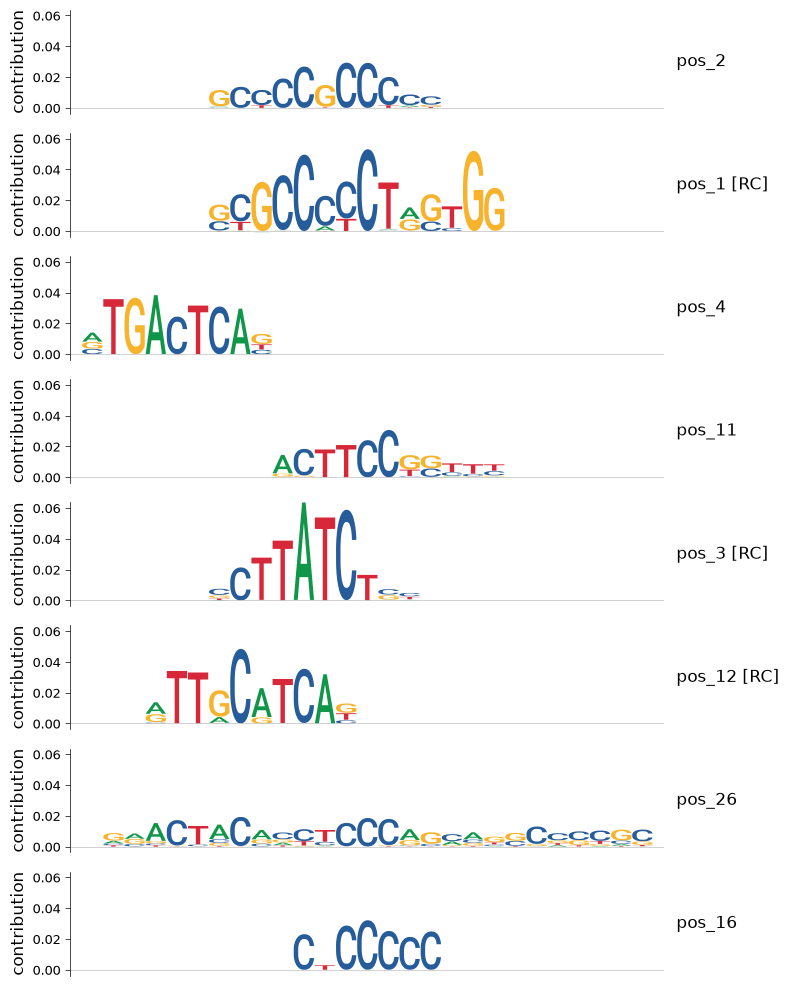

In [7]:
fig = um.view_motifs(found.patterns["cwm"].to_list()[:8], names_pos="right", show_positions=False,
                     figsize=(8, 10))

## Naming the patterns

[`name_motifs()`][universalmotif.name_motifs] names each pattern by the
JASPAR motif it resembles most. To compare with TF-MoDISco, we also find each
pattern's closest TF-MoDISco pattern by CWM cosine. Those patterns were found
in all 270,000 of the model's regions, not just the 9,000 or so of
chromosome 1 used here:

In [8]:
jaspar = um.read_meme(jaspar_path)
pats = found.patterns
names = um.name_motifs(pats["motif"].to_list(), jaspar, top=1, nthreads=2)

modisco = [m.replace(name=f"pattern_{m.name.rsplit('_', 1)[1]}")
           for m in um.read_modisco(modisco_path) if m.name.startswith("pos")]
cmp = um.compare_motifs(pats["cwm"].to_list() + modisco, compare_to=list(range(pats.height)), qvalue=1,
                        nthreads=2)
closest = (cmp.filter(pl.col("target_i") >= pats.height).sort("score", descending=True)
           .group_by("subject_i", maintain_order=True).first())
(
    pats.with_row_index("i").select("i", "pattern", "consensus", "seqlets")
    .join(names.select(i=pl.col("motif_i").cast(pl.UInt32), jaspar="altname"), on="i", how="left")
    .join(closest.select(i="subject_i", tfmodisco="target", cosine=pl.col("score").round(2)), on="i", how="left")
    .drop("i")
)

pattern,consensus,seqlets,jaspar,tfmodisco,cosine
str,str,i64,str,str,f64
"""pos_p1""","""GCYCCGCCCCY""",3697,"""PATZ1""","""pattern_2""",0.99
"""pos_p2""","""CCASYAGRKGGCRS""",2743,"""CTCF""","""pattern_1""",1.0
"""pos_p3""","""RTGACTCAB""",1771,"""FOSL2::JUN""","""pattern_3""",0.98
"""pos_p4""","""ACTTCCTSTTY""",1232,"""Spi1""","""pattern_8""",0.97
"""pos_p5""","""RNAGATAAGR""",1027,"""GATA2""","""pattern_0""",0.97
"""pos_p6""","""MTGATGCAAY""",623,"""ATF4""","""pattern_7""",0.99
"""pos_p7""","""RRACTACANYTCCCAGMAKSCCNYGC""",484,"""Thap11""","""pattern_12""",0.94
"""pos_p8""","""CTCCCCC""",445,"""Wt1""","""pattern_2""",0.76
"""pos_p9""","""NYTGGCASNNRGCCARG""",430,"""NFIB""","""pattern_11""",0.98


Most patterns match a TF-MoDISco pattern closely, and their JASPAR names are
the factors of the [TF-MoDISco results](tfmodisco.ipynb) guide. Among them
are CTCF, the GC box of SP and KLF, the MAF recognition element of NF-E2,
GATA, ETS, ATF4, NF-Y, NFI, NRF1 and THAP11. The NFI palindrome comes from the
second search. Its sites are a small share of all seqlets, but a larger share
of those the first motifs left unreached.

[`plot_modisco()`][universalmotif.plot_modisco] draws the patterns as the
same report it draws for TF-MoDISco results. Each pattern gets a row with its
number of seqlets, its logos and its closest database motifs. With `html`, it
also writes the report as an HTML page, whose columns sort and whose rows
open to show each pattern's CWMs.
[`ContributionMotifs.report()`][universalmotif.ContributionMotifs.report]
writes just the page:

```python
fig = um.plot_modisco(found, database=jaspar, patterns=8, html="k562-motifs.html")
```

## Compared with TF-MoDISco

To compare the two on equal terms, both were run on the same regions of this
model. Three random sets of 21,000 of its 500-base windows each went to
TF-MoDISco (modisco-lite 3.0.0 with its default settings) and to
`contribution_motifs()`, on two threads of an Apple M5 Pro. TF-MoDISco needs
hypothetical scores, so `contribution_motifs()` was run both with and without
them. Each run's positive patterns were compared with the 44 positive
patterns of the model's published TF-MoDISco results, which come from all
270,000 of its regions. A pattern counts as recovered when a run has a CWM
with a cosine of at least 0.8 to it, or of at least 0.9 for a close match.
The table gives the means of the three sets:

| Run | Time | Peak memory | Recovered at 0.8 | Recovered at 0.9 |
| --- | --- | --- | --- | --- |
| TF-MoDISco | 41 min | 2.8 GB | 25 | 15.7 |
| `contribution_motifs()`, with hypothetical scores | 16 s | 0.85 GB | 28.3 | 15.7 |
| `contribution_motifs()`, observed scores only | 10 s | 0.7 GB | 26.7 | 15.7 |
| `contribution_motifs()` on all 187,000 windows, observed scores only | 2 min | 2.5 GB | 29 | 17 |

On the same regions, `contribution_motifs()` recovers a few more of the
published patterns, and matches as many of them closely, about 150 times
faster. Its speed also makes the whole set of regions practical. TF-MoDISco
is often run on a sample of around 30,000 regions to keep its run time down,
but rare patterns have few seqlets in a sample. On all 187,000 windows,
`contribution_motifs()` recovers 16 or 17 of the 17 patterns that
TF-MoDISco found in each set of 21,000.

## Where the model used each motif

A scan of the sequence finds every site that looks like a motif.
[`scan_contributions()`][universalmotif.scan_contributions] instead matches
a CWM against the contribution scores, so it finds the sites the model used.
A window is a hit when two measures reach the motif's thresholds:

- its similarity, the cosine between its scores and the CWM;
- its importance, the sum of its absolute scores as a fraction of the CWM's.

`contribution_motifs()` sets these thresholds from each motif's own sites in
the seqlets, so that 95% of them would pass each one. Its `hits` table holds
the hits of every motif in all the windows:

In [9]:
print(found.hits.height, "hits in", len(seqs), "windows")
found.thresholds.head(8)

78979 hits in 21292 windows


motif,min_similarity,min_importance
str,f64,f64
"""pos_1""",0.806524,0.449229
"""pos_2""",0.843886,0.651154
"""pos_4""",0.909722,0.454551
"""pos_3""",0.943652,0.410695
"""pos_r30""",0.660534,1.572724
"""pos_11""",0.707448,0.666721
"""pos_12""",0.78162,0.453308
"""pos_13""",0.870663,0.634568


Every motif is matched on its own, so similar motifs can each have a hit at
one site. To draw a single window, we match again with the same thresholds,
keeping only the best hit where hits of different motifs overlap. We pick the
window with the most different motifs among the first 3,000:

In [10]:
hits = um.scan_contributions(found.cwms, scores[:3000], sequences=seqs[:3000], thresholds=found.thresholds,
                             no_overlaps_across_motifs=True, nthreads=2)
row = int(hits.group_by("sequence_i").agg(pl.col("motif").n_unique().alias("n"))
          .sort("n", "sequence_i", descending=[True, False])["sequence_i"][0])
here = hits.filter(pl.col("sequence_i") == row)
here.select("motif", "start", "end", "strand", "match", "similarity", "importance")

motif,start,end,strand,match,similarity,importance
str,i64,i64,str,str,f64,f64
"""pos_4""",174,183,"""-""","""CTGACTCAT""",0.98283,1.270562
"""pos_17""",337,353,"""+""","""CAAGATGGCGAACACC""",0.9025,0.734522
"""pos_34""",270,282,"""-""","""ATCAGTTACGGC""",0.565825,0.789186
"""pos_43""",208,220,"""+""","""GGCCACGTGGCT""",0.88079,1.067684
"""pos_r31""",224,232,"""+""","""CTAACCCG""",0.53288,0.775945
"""pos_r31""",314,322,"""+""","""TACTGGCG""",0.541982,0.628491
"""pos_r34""",237,251,"""-""","""ACGTCACTTCTCCC""",0.848058,0.947244


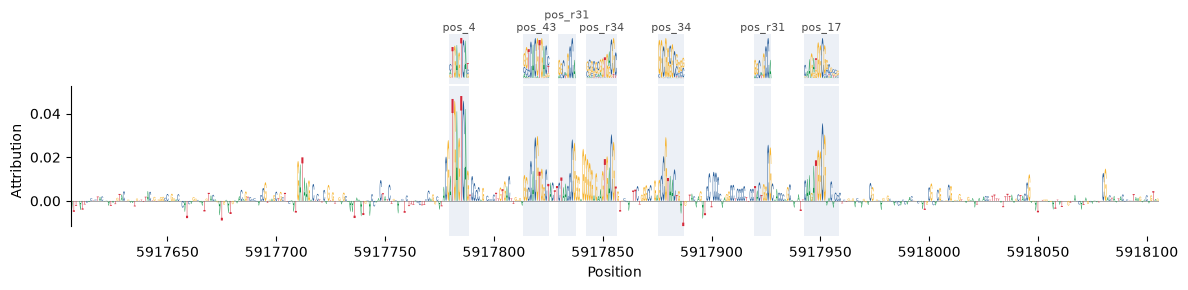

In [11]:
c, s, e = windows.row(row)
ax = um.view_attributions(scores[row], seqs[row], start=s, hits=here, motifs=found.cwms, figsize=(12, 3))

## Choosing the settings

The defaults aim at the patterns a model has learned. They keep a motif when
it adds at least 0.25% of the seqlets and its CWM differs from those kept.
For a short list of motifs that reach as many seqlets as possible, such as
for scanning new sequences, keep motifs that add at least 1% and drop the
CWM comparison:

In [12]:
short = um.contribution_motifs(scores, seqs, seed=1, nthreads=2, min_gain=0.01, max_similarity=None)
short.motifs.select("name", "consensus", "seqlets", "gain", "cumulative")

name,consensus,seqlets,gain,cumulative
str,str,i64,f64,f64
"""pos_1""","""CCASYAGRKGGCRS""",2528,0.154353,0.154353
"""pos_2""","""GCCCCGCCCCC""",2240,0.128587,0.282941
"""pos_r4""","""STGATAASR""",1425,0.086213,0.369154
"""pos_4""","""RTGACTCA""",1423,0.085175,0.454329
"""pos_3""","""RNAGATAAGN""",1381,0.042496,0.496825
"""pos_11""","""ACTTCCTSTTY""",719,0.039077,0.535902
"""pos_r2""","""GRCCACGCCCMC""",830,0.027903,0.563805
"""pos_12""","""MTGATGCAAY""",433,0.025095,0.5889
"""pos_13""","""RGCCAATSRGMR""",440,0.024973,0.613872


Here `gain` is the share of seqlets each motif adds, in the order chosen, and
`cumulative` the share reached so far. Rare motifs now drop out, while
similar motifs stay because each catches sites the others miss.

Other options change one step each:

| Option | What it does |
| --- | --- |
| `hypothetical` | Adds a search on seqlets rewritten in the letters the model prefers, which finds degenerate sites such as NFI more reliably |
| `null_scores` | The model's scores for shuffled sequences, a better null for calling seqlets than the shuffled scores |
| `stability=4` | Keeps only motifs found again in most searches of half the seqlets, at the cost of rare motifs |
| `sign="both"` | Also searches the negative seqlets, which are only reliable with `null_scores` |
| `seqlets` | Seqlets to use instead of calling them, such as TF-MoDISco's |
| `rounds=1`, `gapped=False`, `hits=False` | Leave out the second search, the composites or the matching, for a quicker call |

The bigWig track holds only the scores of the bases present, so we can't
show `hypothetical` here. [`read_contributions()`][universalmotif.read_contributions]
reads hypothetical scores from the files of chromBPNet and of ENCODE. The
[experiments on a model](model-experiments.ipynb) guide shows how to compute
scores, and the scores of shuffled sequences, with a model of your own.

Scores from a model's profile head are spikier than those of its counts
head, with a few strong bases between weak ones. Seqlets called with
`min_len=2` and `threshold=0.05` suit them better:

```python
seqlets = um.call_seqlets(scores, seqs, min_len=2, threshold=0.05)
found = um.contribution_motifs(scores, seqs, seqlets=seqlets)
```

## Step by step

Each step of `contribution_motifs()` is a function of its own, for more
control over any of them. [`call_seqlets()`][universalmotif.call_seqlets]
calls a stretch a seqlet when its total contribution is unlikely under a
null built from the scores shuffled. The same must hold for every stretch inside
it, so a seqlet holds no run of unremarkable bases:

In [13]:
seqlets = um.call_seqlets(scores, seqs, seed=1, nthreads=2)
seqlets.group_by("sign").agg(pl.len(), pl.col("end").sub(pl.col("start")).median().alias("median width"))

sign,len,median width
str,u32,f64
"""+""",16378,17.0
"""-""",112331,13.0


Negative seqlets come out far more numerous than positive ones. That says
more about the null than about the model. The false discovery rate comes
from the scores shuffled within each window, which is too lenient for faint
negative scores. The model's scores for shuffled sequences avoid this.

The search, refinement and selection are then ordinary calls, with the
seqlets as the sites the motifs should reach:

In [14]:
pos = seqlets.filter(pl.col("sign") == "+")
targets = [seqs[i][max(s - 3, 0):e + 3] for i, s, e in pos.select("sequence_i", "start", "end").iter_rows()]
plain = um.motif_finder(targets, nmotifs=20, seed=1, nthreads=2)
refined = um.refine_motifs(plain, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen = um.select_motifs(refined, seqs, sites=pos, min_overlap=5, nthreads=2)
chosen.select("motif", "rank", "targets", "gain", "kept").head(10)

motif,rank,targets,gain,kept
str,u32,u64,f64,bool
"""motif_1""",1,2411,0.14721,true
"""motif_3""",2,2061,0.121504,true
"""motif_2""",3,1937,0.11723,true
"""motif_4""",4,1556,0.093296,true
"""motif_6""",5,703,0.03871,true
"""motif_7""",6,570,0.03291,true
"""motif_10""",7,507,0.027293,true
"""motif_8""",8,464,0.026255,true
"""motif_9""",9,440,0.025156,true


Here `motif_finder()` compares the seqlets with three shuffles of themselves,
its default background. `contribution_motifs()` uses windows from the regions
away from any seqlet instead. That keeps sequence common to all accessible
regions, such as GC-rich stretches, from looking enriched.

## Saving disk space

Hypothetical scores take four numbers per base, so for a genome-wide set of
regions they can fill far more disk than the sequences themselves. They are
only needed to idealize the seqlets, and
[`idealize_sequences()`][universalmotif.idealize_sequences] looks at one
position at a time. Each batch of regions can therefore be idealized as the
model scores it, and its hypothetical scores dropped. Only the observed
scores, one number per base, and the idealized letters are kept:

```python
observed, letters, ideal = [], [], []
for seqs, hyp in batches:  # each batch's sequences and their hypothetical scores
    onehot = um.one_hot(seqs)
    observed.append((hyp * onehot).sum(axis=1).astype(np.float16))
    letters += seqs
    ideal += um.idealize_sequences(seqs, hyp)
found = um.contribution_motifs(np.concatenate(observed), letters, idealized=ideal)
```

When even the observed scores are too many to keep, seqlets can be called
batch by batch, as long as every batch has the same null scores. The model's
scores for shuffled sequences make the best, and a first batch's scores
shuffled also work. Each batch is called with `fdr=None` to keep every
candidate, and the null scores are called once the same way.
[`seqlet_fdr()`][universalmotif.seqlet_fdr] then applies one false discovery
rate to them all, which gives exactly the seqlets of a single call:

```python
null = np.random.default_rng(1).permuted(first_batch, axis=1)
candidates, positions = [], 0
for start, obs, seqs in batches:  # the first row of each batch, and its scores and sequences
    found = um.call_seqlets(obs, seqs, null_scores=null, fdr=None)
    candidates.append(found.with_columns(pl.col("sequence_i") + start))
    positions += obs.size
null_seqlets = um.call_seqlets(null, null_scores=null, fdr=None)
seqlets = um.seqlet_fdr(pl.concat(candidates), null_seqlets, positions=positions, null_positions=null.size)
```

Only the scores within 30 bases of a seqlet then need to be kept. On the
187,000 windows of this model, that is a tenth of all positions, and
`contribution_motifs()` found exactly the same motifs from them. Without the
rest of the scores, though, it cannot find hits outside those windows. A
second pass of the model, scanned with
[`scan_contributions()`][universalmotif.scan_contributions] and the motifs'
CWMs, finds them instead.